# Beyond Diabetes: charts (Phase 5)

Chart 1, the open areas (hero, 21 Nov): industry-led share of 2023–25 trial starts in the 11 busiest areas, against the white-space bar. Written for a hiring manager on the portfolio site: plain disease names, no jargon. Data: `data/results/05_q2_white_space.csv` (step 05), `03_trial_indications.csv` (trial count) and the GBD PCOS file in `data/external/gbd/`.

Chart 2, the lag timeline (chart 1 until 21 Nov; reworked 21 Nov): for the same 11 areas, the year of the first researcher-led and first company-led trial, and the gap between them. Lag lines only (trial dots dropped), axis to 2025. Data: `data/results/04_q1_spread.csv` (first academic and industry-led year) and `05_q2_white_space.csv` (rows). `11_hero_timeline.csv` is no longer used by any chart.

In [1]:
# Phase 5 charts. Each chart reads only data/results/ CSVs, built by sql/pipeline/run_all.sh.
# Footnote numbers are read from the checks at the end of each pipeline step, never typed from memory.
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repo root
os.makedirs("charts", exist_ok=True)

# Plain names for a non-specialist reader, shared by all charts (decided 21 Nov); unlisted names are already plain
PLAIN = {
    "Obstructive sleep apnoea": "Sleep apnea",
    "Hypertension": "High blood pressure",
    "MASLD": "Fatty liver disease",
    "ASCVD": "Heart & artery disease",
    "CKD": "Kidney disease",
}

## Chart 1: the open areas (hero)

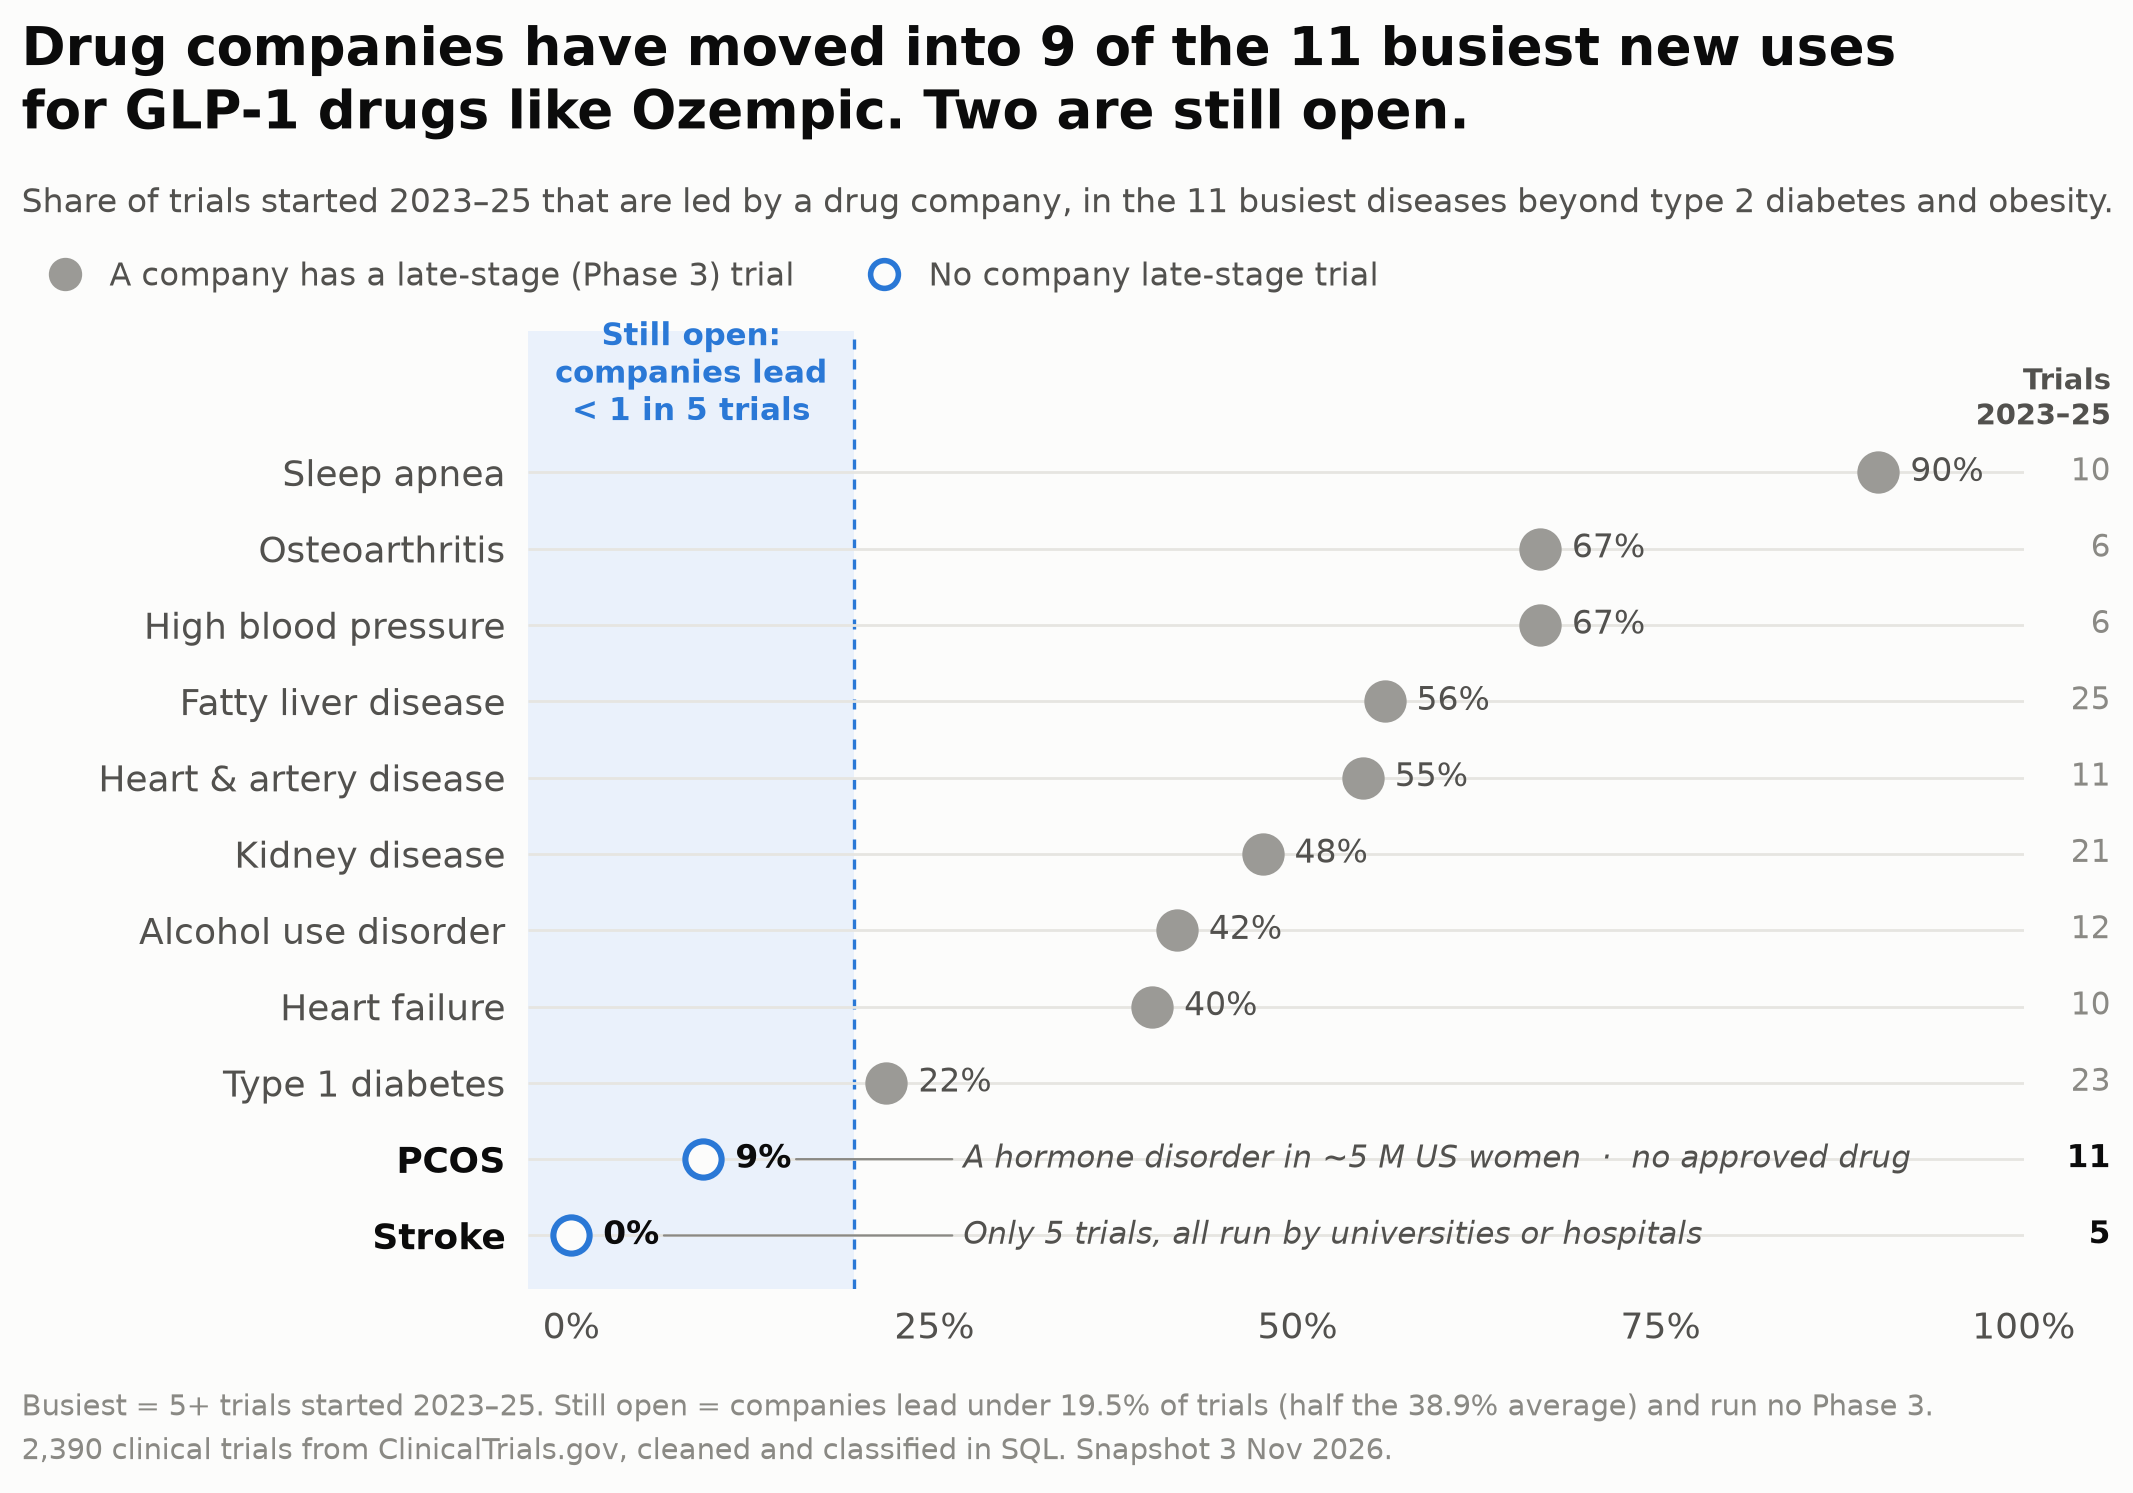

In [2]:
# Chart 1: the open areas (hero, 21 Nov). Reads data/results/ and data/external/gbd/ only;
# writes charts/01_hero_open_areas.png and .svg
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

MIN_RECENT = 5          # rows: indications with 5+ trial starts 2023-25, Q2's size rule

ws = pd.read_csv("data/results/05_q2_white_space.csv")
df = ws[ws["recent_trials"] >= MIN_RECENT].copy()
df["ph3"] = (df["industry_ph3_active"] + df["industry_ph3_completed"]) > 0
df["open"] = df["verdict"].eq("white space")
BAR = df["bar_pct"].iloc[0]                 # 19.5% = half the 38.9% baseline

df["label"] = df["indication"].map(PLAIN).fillna(df["indication"])
df = df.sort_values("industry_share_pct").reset_index(drop=True)

# Numbers in the text, read from files, never typed
n_trials = pd.read_csv("data/results/03_trial_indications.csv")["nct_id"].nunique()
gbd = pd.read_csv("data/external/gbd/gbd_pcos_prevalence_2023_eu27_uk_us_2026-11-14.csv")
pcos_us_m = gbd.query("location_name == 'United States of America' and metric_name == 'Number'")["val"].iloc[0] / 1e6
n_entered = int((~df["open"]).sum())
assert n_entered == len(df) - 2 and len(df) == 11, "headline says 9 of 11: recheck the title"

def pct(x):             # round half up (Python's round() sends 54.5 to 54)
    return f"{int(x + 0.5)}%"

# Colours (reference palette slot 1 for the open areas, the academic colour in chart 2)
SURFACE = "#fcfcfb"; INK = "#0b0b0b"; INK2 = "#52514e"; MUTED = "#8a8984"
GREY = "#9b9a96"; ACCENT = "#2a78d6"; GRID = "#e6e5e1"; ZONE = "#eaf1fb"

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 13})
fig, ax = plt.subplots(figsize=(11, 7.6), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

# "Still open" zone: left of the white-space bar
ax.axvspan(-3, BAR, color=ZONE, zorder=0, lw=0)
ax.axvline(BAR, color=ACCENT, lw=1.2, ls=(0, (3, 3)), zorder=1)
ax.text(BAR / 2 - 1.5, len(df) - 0.45, "Still open:\ncompanies lead\n< 1 in 5 trials",
        ha="center", va="bottom", fontsize=11, color=ACCENT, fontweight="bold")

for i, r in df.iterrows():
    c = ACCENT if r["open"] else GREY
    ax.hlines(i, -3, 100, color=GRID, lw=1, zorder=1)
    ax.scatter(r["industry_share_pct"], i, s=170, zorder=3,
               facecolor=c if r["ph3"] else SURFACE, edgecolor=c, linewidth=2.2)
    ax.text(r["industry_share_pct"] + 2.2, i, pct(r["industry_share_pct"]), va="center", fontsize=12,
            color=INK if r["open"] else INK2, fontweight="bold" if r["open"] else "normal")

ax.set_yticks(range(len(df)), df["label"])

# Quiet trial-count column at the right edge (21 Nov): shows size without new ink in the plot
COUNT_X = 106
ax.text(COUNT_X, len(df) - 0.5, "Trials\n2023–25", ha="right", va="bottom", fontsize=10.5,
        color=INK2, fontweight="bold", clip_on=False)
for i, r in df.iterrows():
    ax.text(COUNT_X, i, f"{r['recent_trials']}", ha="right", va="center", fontsize=11,
            color=INK if r["open"] else MUTED, fontweight="bold" if r["open"] else "normal",
            clip_on=False)
for t, o in zip(ax.get_yticklabels(), df["open"]):
    t.set_color(INK if o else INK2); t.set_fontweight("bold" if o else "normal")

# PCOS "so what" note (docs/so_what.md: GBD 2023 count; no FDA or EMA approved drug for PCOS itself)
p = df.index[df["indication"] == "PCOS"][0]
ax.annotate(f"A hormone disorder in ~{pcos_us_m:.0f} M US women  ·  no approved drug",
            xy=(df.loc[p, "industry_share_pct"] + 6, p), xytext=(27, p),
            va="center", fontsize=11, color=INK2, style="italic",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
# Stroke note: the thinner lead (headline, decided 18 Nov: 5 trials, 0 industry)
s = df.index[df["indication"] == "Stroke"][0]
assert df.loc[s, "industry_led"] == 0, "Stroke note says all academic: recheck"
ax.annotate(f"Only {df.loc[s, 'recent_trials']} trials, all run by universities or hospitals",
            xy=(df.loc[s, "industry_share_pct"] + 6, s), xytext=(27, s),
            va="center", fontsize=11, color=INK2, style="italic",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax.set_xlim(-3, 100); ax.set_ylim(-0.7, len(df) + 0.85)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"], color=INK2)
ax.tick_params(length=0, pad=8)
for s in ax.spines.values():
    s.set_visible(False)

fig.text(0.02, 0.965, f"Drug companies have moved into {n_entered} of the {len(df)} busiest new uses\n"
         "for GLP-1 drugs like Ozempic. Two are still open.",
         fontsize=19, fontweight="bold", color=INK, va="top")
fig.text(0.02, 0.855, f"Share of trials started 2023–25 that are led by a drug company, in the {len(df)} busiest "
         "diseases beyond type 2 diabetes and obesity.", fontsize=12, color=INK2, va="top")

legend = [
    Line2D([], [], marker="o", ls="", ms=10, mfc=GREY, mec=GREY, mew=2,
           label="A company has a late-stage (Phase 3) trial"),
    Line2D([], [], marker="o", ls="", ms=10, mfc=SURFACE, mec=ACCENT, mew=2,
           label="No company late-stage trial"),
]
fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.012, 0.825), ncol=2,
           frameon=False, fontsize=11.5, labelcolor=INK2, handletextpad=0.4, columnspacing=1.8)

BASE = df["baseline_pct"].iloc[0]
fig.text(0.02, 0.018, f"Busiest = {MIN_RECENT}+ trials started 2023–25. Still open = companies lead under {BAR:g}% "
         f"of trials (half the {BASE:g}% average) and run no Phase 3.\n"
         f"{n_trials:,} clinical trials from ClinicalTrials.gov, cleaned and classified in SQL. "
         "Snapshot 3 Nov 2026.", fontsize=10.5, color=MUTED, linespacing=1.5)

fig.subplots_adjust(left=0.25, right=0.93, top=0.76, bottom=0.13)
fig.savefig("charts/01_hero_open_areas.png", facecolor=SURFACE)
fig.savefig("charts/01_hero_open_areas.svg", facecolor=SURFACE)
plt.show()

## Chart 2: the lag timeline

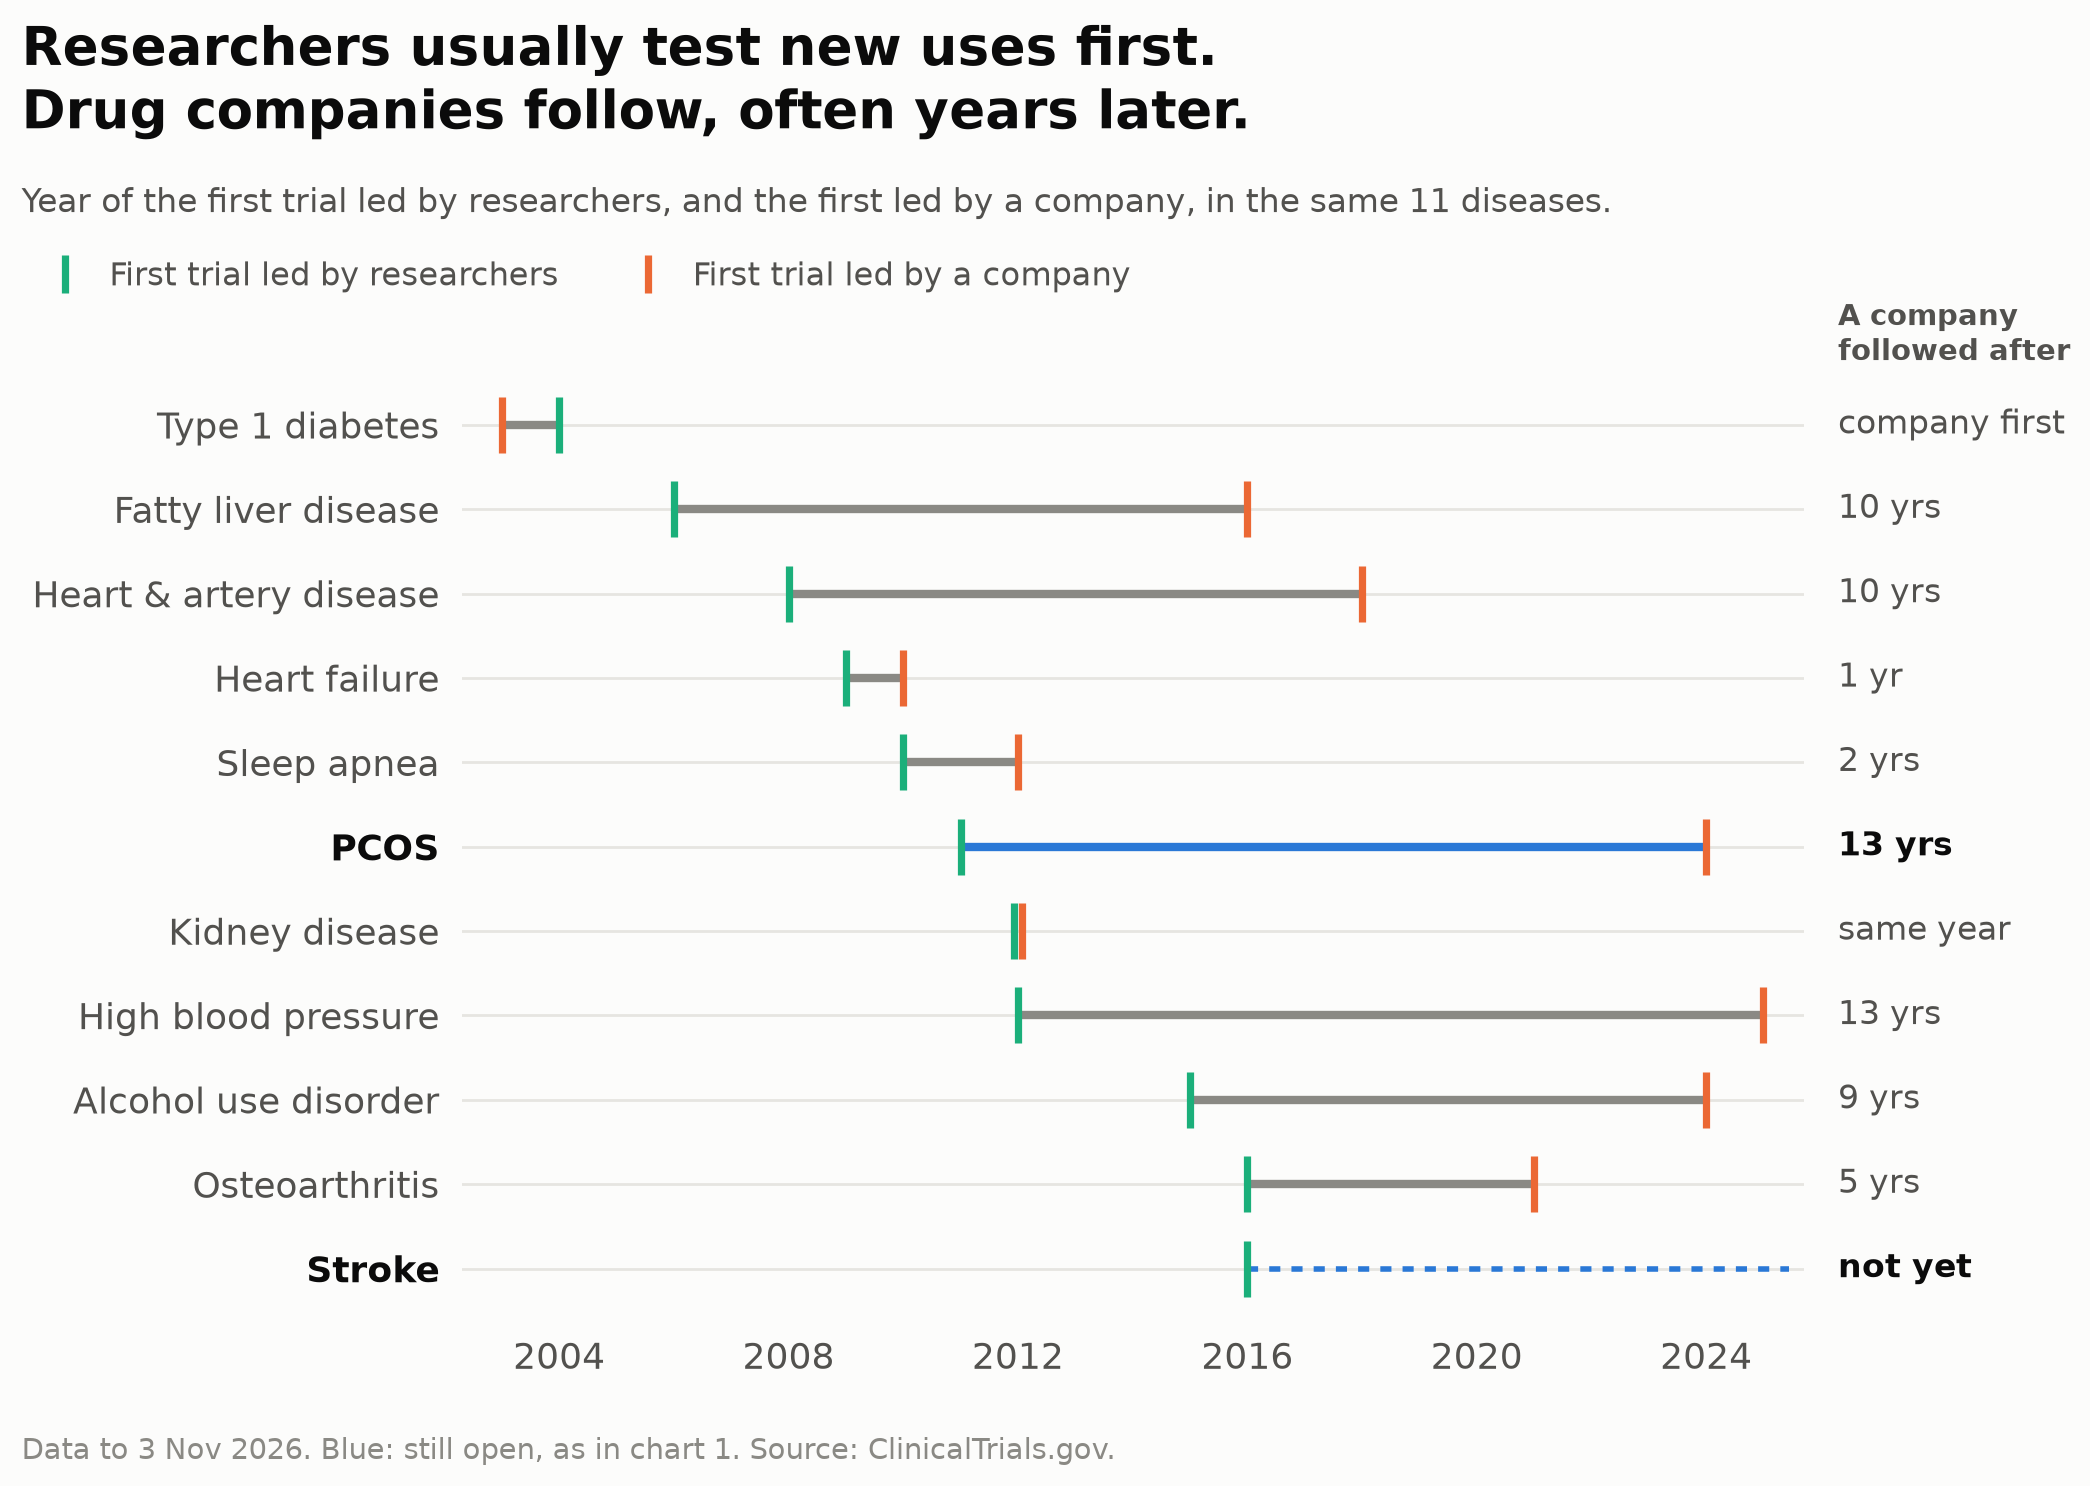

In [3]:
# Chart 2: the lag timeline (21 Nov: chart 1's 11 rows, plain names, lag lines only, no trial dots).
# Reads data/results/ only; writes charts/02_spread_timeline.png and .svg
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIRST_X, LAST_X = 2003, 2025   # axis ends 2025: no first company trial here falls in 2026; data runs to 3 Nov 2026

q1 = pd.read_csv("data/results/04_q1_spread.csv").set_index("indication")
ws = pd.read_csv("data/results/05_q2_white_space.csv")

# Rows: the same 11 as chart 1 (5+ trial starts 2023-25), ordered by first trial
rows = ws.loc[ws["recent_trials"] >= 5, "indication"]
open_areas = set(ws.loc[ws["verdict"].eq("white space"), "indication"])
order = (q1.loc[rows, ["first_year", "trials_all_years"]]
           .sort_values(["first_year", "trials_all_years"], ascending=[True, False]).index.tolist())

# Title claim: companies were not first in most rows (lag > 0 or no company yet)
lag = q1.loc[order, "industry_lag_years"]
n_research_first = int(((lag > 0) | lag.isna()).sum())
assert n_research_first >= 8, "title says researchers usually go first: recheck"
assert not (q1.loc[order, "first_industry_year"] > LAST_X).any(), "a first company trial falls after the last year shown"

# Colours: same as chart 1 (blue = still-open areas, grey = the rest); company = palette slot 2 (orange),
# researchers = slot 3 (aqua), not black, so the marks don't clash with the bold black PCOS/stroke labels.
# Blue/orange/aqua pass the dataviz validator all-pairs (worst CVD dE 9.2); aqua is 2.7:1 on the surface,
# so its meaning is carried by the legend and the years column too
SURFACE = "#fcfcfb"; INK = "#0b0b0b"; INK2 = "#52514e"; MUTED = "#8a8984"; GRID = "#e6e5e1"
GREY = "#8a8984"; ACCENT = "#2a78d6"; RESEARCH = "#1baf7a"; COMPANY = "#eb6834"

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 13})
fig, ax = plt.subplots(figsize=(11, 7.6), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

for y, ind in enumerate(order):
    ax.axhline(y, color=GRID, lw=1, zorder=0)
    line = ACCENT if ind in open_areas else GREY

    # lag line: first researcher-led trial -> first company-led trial (dashed to the edge if none yet)
    a, i = q1.loc[ind, "first_academic_year"], q1.loc[ind, "first_industry_year"]
    if pd.notna(a) and pd.notna(i) and a == i:      # same year: ticks touching, side by side
        a, i = a - 0.065, i + 0.065
    elif pd.notna(a) and pd.notna(i):
        lo, hi = sorted([a, i])
        ax.plot([lo, hi], [y, y], color=line, lw=3, zorder=2, solid_capstyle="butt")
    elif pd.notna(a):
        ax.plot([a, LAST_X + 0.45], [y, y], color=line, lw=2, ls=(0, (2, 2)), zorder=2)
    if pd.notna(a):
        ax.scatter([a], [y], marker="|", s=420, color=RESEARCH, linewidth=2.6, zorder=5)
    if pd.notna(i):
        ax.scatter([i], [y], marker="|", s=420, color=COMPANY, linewidth=2.6, zorder=5)

    # right column: years until a company followed
    l = q1.loc[ind, "industry_lag_years"]
    txt = ("not yet" if pd.isna(l) else "company first" if l < 0 else "same year" if l == 0
           else "1 yr" if l == 1 else f"{int(l)} yrs")
    bold = ind in open_areas
    ax.text(LAST_X + 1.3, y, txt, va="center", ha="left", fontsize=12,
            color=INK if bold else INK2, fontweight="bold" if bold else "normal")

ax.set_yticks(range(len(order)), [PLAIN.get(ind, ind) for ind in order])
for t, ind in zip(ax.get_yticklabels(), order):
    bold = ind in open_areas
    t.set_color(INK if bold else INK2); t.set_fontweight("bold" if bold else "normal")
ax.set_ylim(len(order) - 0.4, -0.75)
ax.set_xlim(FIRST_X - 0.7, LAST_X + 0.7)
ax.set_xticks(range(2004, 2027, 4))
ax.tick_params(axis="x", colors=INK2, length=0, pad=8)
ax.tick_params(axis="y", length=0, pad=8)
for s in ax.spines.values():
    s.set_visible(False)
ax.text(LAST_X + 1.3, -0.65, "A company\nfollowed after", fontsize=10.5, color=INK2,
        fontweight="bold", va="bottom", clip_on=False)

fig.text(0.02, 0.965, "Researchers usually test new uses first.\n"
         "Drug companies follow, often years later.",
         fontsize=19, fontweight="bold", color=INK, va="top")
fig.text(0.02, 0.855, "Year of the first trial led by researchers, and the first led by a company, "
         "in the same 11 diseases.", fontsize=12, color=INK2, va="top")

leg = [Line2D([], [], marker="|", ls="", markersize=14, markeredgewidth=2.6, color=RESEARCH,
              label="First trial led by researchers"),
       Line2D([], [], marker="|", ls="", markersize=14, markeredgewidth=2.6, color=COMPANY,
              label="First trial led by a company")]
fig.legend(handles=leg, loc="upper left", bbox_to_anchor=(0.012, 0.825), ncol=2, frameon=False,
           fontsize=11.5, labelcolor=INK2, handletextpad=0.4, columnspacing=1.8)

fig.text(0.02, 0.018, "Data to 3 Nov 2026. Blue: still open, as in chart 1. "
         "Source: ClinicalTrials.gov.", fontsize=10.5, color=MUTED)

fig.subplots_adjust(left=0.22, right=0.83, top=0.74, bottom=0.11)
fig.savefig("charts/02_spread_timeline.png", facecolor=SURFACE)
fig.savefig("charts/02_spread_timeline.svg", facecolor=SURFACE)
plt.show()